In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/eduai-audit/data/"
df = pd.read_csv(path + 'studentInfo.csv')
df.head()


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


# Первичный EDA

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              32593 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB


In [7]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


code_module
code_module
BBB    7909
FFF    7762
DDD    6272
CCC    4434
EEE    2934
GGG    2534
AAA     748
Name: count, dtype: int64

code_presentation
code_presentation
2014J    11260
2013J     8845
2014B     7804
2013B     4684
Name: count, dtype: int64

gender
gender
M    17875
F    14718
Name: count, dtype: int64

region
region
Scotland                3446
East Anglian Region     3340
London Region           3216
South Region            3092
North Western Region    2906
West Midlands Region    2582
South West Region       2436
East Midlands Region    2365
South East Region       2111
Wales                   2086
Yorkshire Region        2006
North Region            1823
Ireland                 1184
Name: count, dtype: int64

highest_education
highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64

imd_band
imd

In [26]:
df.isnull().sum()
df['imd_band'].value_counts(dropna=False)
(df == '?').sum()
df = df.replace('?', np.nan)

In [33]:
df.isnull().sum()
pd.crosstab(df['imd_band'].isna(), df['final_result'], normalize='index').mul(100).round(2)
df['imd_band_clean'] = df['imd_band'].fillna('Unknown')

In [14]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['final_result'].value_counts(normalize=True) * 100

,proportion
final_result,
Pass,37.925321
Withdrawn,31.160065
Fail,21.636548
Distinction,9.278066


In [22]:
# H1: Доля студентов, прекращающих обучение на курсе, различается в зависимости от уровня предыдущего образования.
pd.crosstab(df['highest_education'], df['final_result'], normalize='index')*100

#Гипотеза предварительно подтверждается

final_result,Distinction,Fail,Pass,Withdrawn
highest_education,,,,
A Level or Equivalent,10.651477,19.273763,41.381274,28.693485
HE Qualification,14.735729,16.701903,41.437632,27.124736
Lower Than A Level,5.525156,26.037392,33.325733,35.111719
No Formal quals,4.610951,27.377522,25.072046,42.939481
Post Graduate Qualification,28.115016,10.862620,37.380192,23.642173


In [35]:
#H2: Доля Withdrawn различается между студентами из районов с разным уровнем социально-экономической депривации.
pd.crosstab(df['imd_band_clean'], df['final_result'], normalize='index').mul(100).round(2)

#Гипотеза предварительно подтверждается

final_result,Distinction,Fail,Pass,Withdrawn
imd_band_clean,,,,
0-10%,5.07,27.67,30.08,37.18
10-20,5.43,25.94,33.19,35.44
20-30%,7.20,23.10,33.55,36.15
30-40%,8.90,22.15,38.01,30.94
40-50%,9.00,21.41,37.59,32.00
50-60%,9.51,22.44,39.28,28.78
60-70%,10.29,18.52,41.62,29.57
70-80%,10.87,20.81,40.64,27.68
80-90%,11.88,17.92,42.18,28.02


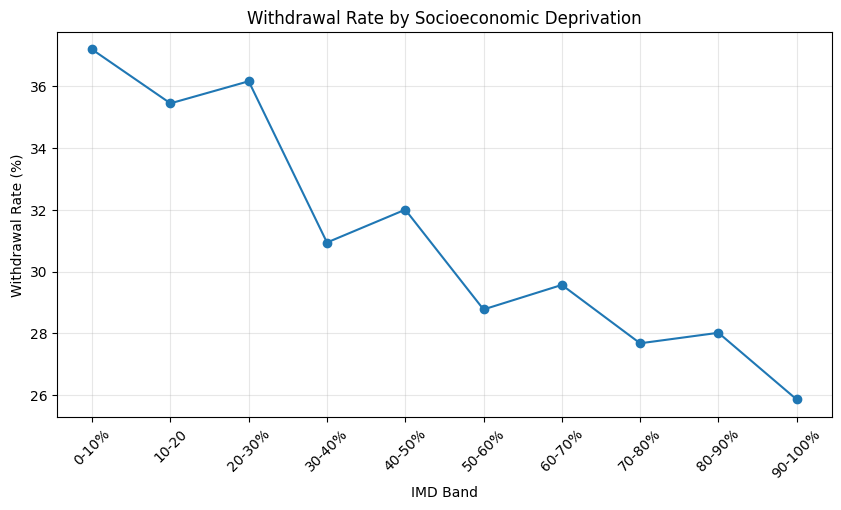

In [50]:
import matplotlib.pyplot as plt

imd_order = [
    "0-10%", "10-20", "20-30%", "30-40%",
    "40-50%", "50-60%", "60-70%",
    "70-80%", "80-90%", "90-100%"
    ]

withdrawal_rate = (df[df['imd_band_clean'] != 'Unknown']
                    .groupby('imd_band_clean')['final_result']
                    .apply(lambda x: (x == 'Withdrawn').mean() * 100))

withdrawal_rate = withdrawal_rate.reindex(imd_order)

plt.figure(figsize=(10, 5))
plt.plot(withdrawal_rate.index, withdrawal_rate.values, marker="o")
plt.xlabel("IMD Band")
plt.ylabel("Withdrawal Rate (%)")
plt.title("Withdrawal Rate by Socioeconomic Deprivation")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()


age_band
0-35     22944
35-55     9433
55<=       216
Name: count, dtype: int64


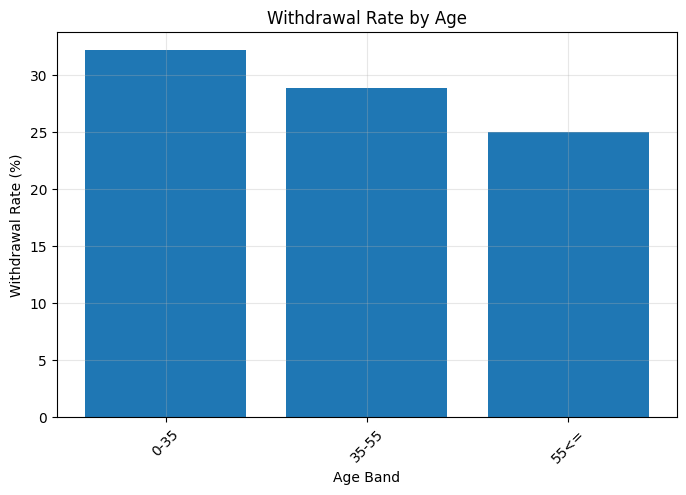

In [62]:
print(df['age_band'].value_counts())

age_rate = (df.groupby('age_band')['final_result']
            .apply(lambda x: (x == 'Withdrawn').mean() * 100))

plt.figure(figsize=(8, 5))
plt.bar(age_rate.index, age_rate.values)
plt.xlabel("Age Band")
plt.ylabel("Withdrawal Rate (%)")
plt.title("Withdrawal Rate by Age")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

gender
M    17875
F    14718
Name: count, dtype: int64


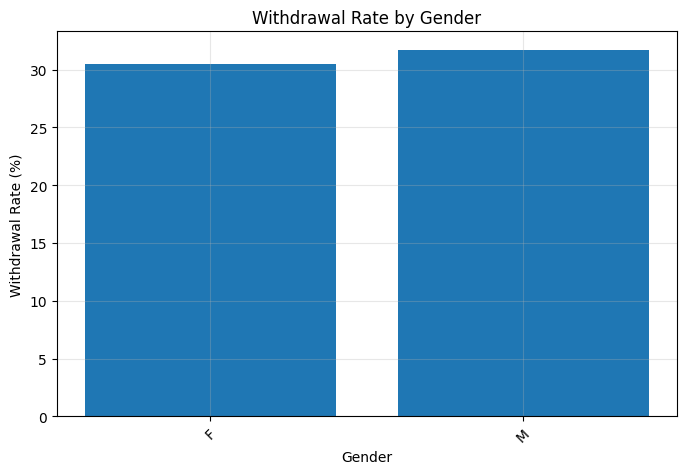

In [66]:
print(df['gender'].value_counts())

gender_rate = (df.groupby('gender')['final_result']
              .apply(lambda x: (x == 'Withdrawn').mean() * 100))

plt.figure(figsize=(8, 5))
plt.bar(gender_rate.index, gender_rate.values)
plt.xlabel("Gender")
plt.ylabel("Withdrawal Rate (%)")
plt.title("Withdrawal Rate by Gender")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

# Статистический анализ

Связан ли imd_band с прекращением обучения сам по себе или наблюдаемая связь частично объясняется предыдущим образованием?

In [67]:
pd.crosstab(
    df["imd_band_clean"],
    df["highest_education"],
    normalize="index"
).mul(100).round(2)

#Студенты из более депривированных районов чаще имеют низкий уровень предыдущего образования.

highest_education,A Level or Equivalent,HE Qualification,Lower Than A Level,No Formal quals,Post Graduate Qualification
imd_band_clean,,,,,
0-10%,39.02,10.54,48.23,2.20,0.00
10-20,41.52,10.24,46.22,1.68,0.34
20-30%,39.85,13.82,43.49,2.30,0.55
30-40%,44.45,13.39,40.41,1.58,0.17
40-50%,45.76,13.97,39.90,0.21,0.15
50-60%,45.01,13.51,40.40,0.58,0.51
60-70%,46.27,14.46,37.87,0.69,0.72
70-80%,45.68,16.22,37.76,0.17,0.17
80-90%,45.15,18.03,35.88,0.00,0.94


In [77]:
#Сохранится ли связь между IMD и прекращением обучения, если мы учтём предыдущий уровень образования?
#1 — Withdrawn.
#0 — не Withdrawn.

df['dropout'] = (df['final_result'] == 'Withdrawn').astype(int)
reg_df = df[['id_student', 'dropout', 'imd_band_clean', 'highest_education']].copy()

In [78]:
import statsmodels.formula.api as smf

model1 = smf.logit(formula='dropout ~ C(imd_band_clean)',data=reg_df).fit()
print(model1.summary())

Optimization terminated successfully.
         Current function value: 0.616443
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                dropout   No. Observations:                32593
Model:                          Logit   Df Residuals:                    32582
Method:                           MLE   Df Model:                           10
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                0.006338
Time:                        15:18:49   Log-Likelihood:                -20092.
converged:                       True   LL-Null:                       -20220.
Covariance Type:            nonrobust   LLR p-value:                 2.559e-49
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -0.5245      0.036    -14.587      0.000

In [79]:
model2 = smf.logit(formula='dropout ~ C(imd_band_clean) + C(highest_education)', data=reg_df).fit()
print(model2.summary())

Optimization terminated successfully.
         Current function value: 0.614078
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                dropout   No. Observations:                32593
Model:                          Logit   Df Residuals:                    32578
Method:                           MLE   Df Model:                           14
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                 0.01015
Time:                        15:21:04   Log-Likelihood:                -20015.
converged:                       True   LL-Null:                       -20220.
Covariance Type:            nonrobust   LLR p-value:                 7.673e-79
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                 

In [80]:
odds_ratios = np.exp(model2.params)
print(odds_ratios)

Intercept                                              0.512310
C(imd_band_clean)[T.10-20]                             0.934961
C(imd_band_clean)[T.20-30%]                            0.970239
C(imd_band_clean)[T.30-40%]                            0.776328
C(imd_band_clean)[T.40-50%]                            0.823389
C(imd_band_clean)[T.50-60%]                            0.703849
C(imd_band_clean)[T.60-70%]                            0.736603
C(imd_band_clean)[T.70-80%]                            0.673986
C(imd_band_clean)[T.80-90%]                            0.690502
C(imd_band_clean)[T.90-100%]                           0.627289
C(imd_band_clean)[T.Unknown]                           0.475527
C(highest_education)[T.HE Qualification]               0.955770
C(highest_education)[T.Lower Than A Level]             1.320919
C(highest_education)[T.No Formal quals]                1.707329
C(highest_education)[T.Post Graduate Qualification]    0.983964
dtype: float64


Социально-экономическая характеристика района проживания и предыдущее образование оба связаны с результатами обучения.

  imd_band_clean      highest_education  dropout_probability
0          0-10%  A Level or Equivalent            33.875993
1          10-20  A Level or Equivalent            32.386276
2         20-30%  A Level or Equivalent            33.202556
3         30-40%  A Level or Equivalent            28.454949
4         40-50%  A Level or Equivalent            29.668132
5         50-60%  A Level or Equivalent            26.502423
6         60-70%  A Level or Equivalent            27.397822
7         70-80%  A Level or Equivalent            25.666576
8         80-90%  A Level or Equivalent            26.131180
9        90-100%  A Level or Equivalent            24.320756


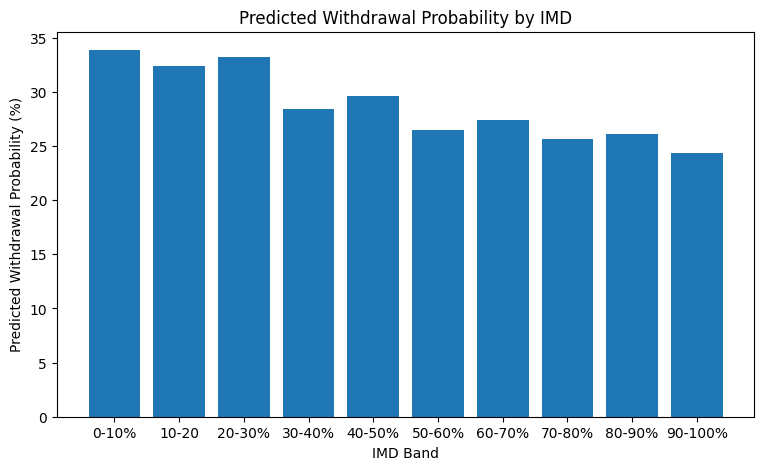

In [87]:
#Представим двух студентов с одинаковым уровнем образования (A Level or Equivalent), но живущих в районах с разным уровнем депривации.
#Какую вероятность прекращения обучения наша модель предскажет каждому из них?

prediction_df = pd.DataFrame({
    "imd_band_clean": [
        "0-10%", "10-20", "20-30%", "30-40%",
        "40-50%", "50-60%", "60-70%",
        "70-80%", "80-90%", "90-100%"
    ],
    "highest_education": ["A Level or Equivalent"] * 10
})

prediction_df['dropout_probability'] = (model2.predict(prediction_df) * 100)
print(prediction_df)

plt.figure(figsize=(9,5))
plt.bar(
    prediction_df["imd_band_clean"],
    prediction_df["dropout_probability"]
)

plt.xlabel("IMD Band")
plt.ylabel("Predicted Withdrawal Probability (%)")
plt.title("Predicted Withdrawal Probability by IMD")

plt.show()


Даже при одинаковом уровне предыдущего образования наша модель оценивает вероятность Withdrawn выше для студентов из более депривированных районов.

#Вывод

Связь социально-экономической депривации района с прекращением обучения сохраняется после статистического учёта предыдущего образования.